<a href="https://colab.research.google.com/github/cs24dse023-netizen/CSL701-cs23_Machine-Learning-Lab/blob/main/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Sandesh kaskar

Batch : CS02


Roll Number :Cs23



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [1]:

# Task 1: Import Libraries and Load Dataset

# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load the dataset
from google.colab import files
uploaded = files.upload()

# Read the CSV file
df = pd.read_csv('Mall_Customers.csv')

# Display the first five rows
print("First 5 rows of the dataset:")
display(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())


Saving Mall_Customers.csv to Mall_Customers.csv
First 5 rows of the dataset:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [2]:

# Task 2: Feature Selection and Standardization

from sklearn.preprocessing import StandardScaler

# Select the required features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Display selected features
print("Selected Features:")
display(X.head())

# Initialize StandardScaler
scaler = StandardScaler()

# Standardize the features
X_scaled = scaler.fit_transform(X)

# Convert scaled data into a DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=['Annual Income (k$)', 'Spending Score (1-100)']
)

# Display standardized features
print("\nStandardized Features:")
display(X_scaled.head())

# Check mean and standard deviation
print("\nMean of scaled features:")
print(X_scaled.mean())

print("\nStandard deviation of scaled features:")
print(X_scaled.std(ddof=0))



Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Standardized Features:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Mean of scaled features:
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Standard deviation of scaled features:
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

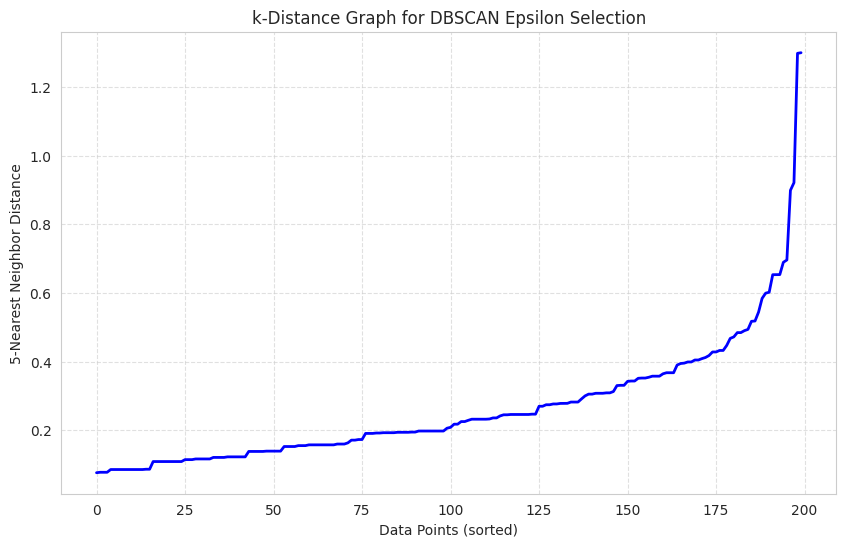

In [3]:

# Task 3: Hyperparameter Selection via k-Distance Graph

from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set min_samples value
min_samples = 5

# Compute nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)

# Calculate distances and indices
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Get the distance to the kth nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

# Plot the sorted k-distances
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

plt.plot(k_distances, color='blue', linewidth=2)
plt.xlabel('Data Points (sorted)')
plt.ylabel(f'{min_samples}-Nearest Neighbor Distance')
plt.title('k-Distance Graph for DBSCAN Epsilon Selection')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

Number of clusters: 7
Number of noise points: 35
Total data points: 200

Cluster Distribution:
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Silhouette Score (excluding noise): 0.5243


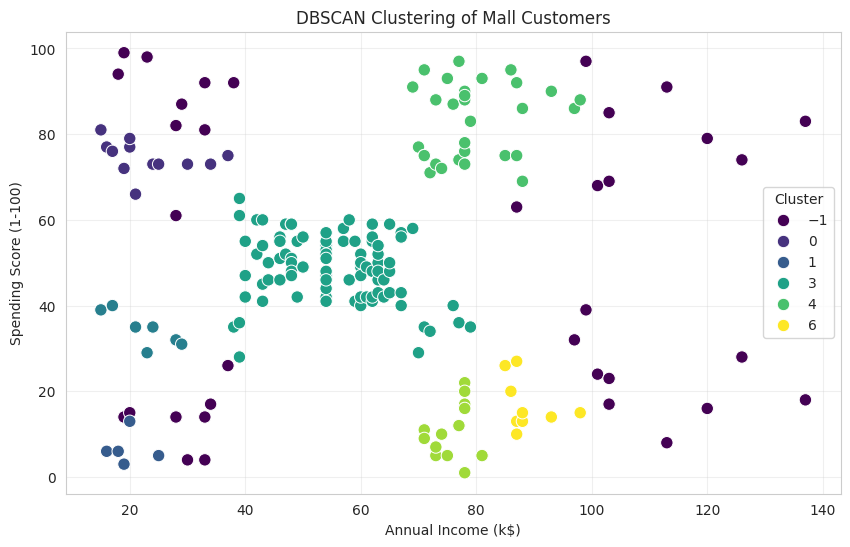

In [4]:

# Task 5: Evaluate DBSCAN Clustering

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Apply DBSCAN
# Change eps according to the elbow point from Task 3
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

# Add cluster labels to the dataset
df['Cluster'] = labels

# Count clusters (excluding noise points labeled -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

# Count noise points
n_noise = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Total data points:", len(labels))

# Display cluster distribution
print("\nCluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

# Calculate Silhouette Score
# Silhouette score requires at least 2 clusters
# and fewer clusters than the number of data points
n_labels = len(set(labels) - {-1})

if 2 <= n_labels < len(labels):
    # Exclude noise points for cluster-quality evaluation
    non_noise = labels != -1
    score = silhouette_score(
        X_scaled[non_noise],
        labels[non_noise]
    )
    print("\nSilhouette Score (excluding noise):", round(score, 4))
else:
    print("\nSilhouette Score cannot be calculated reliably.")
    print("DBSCAN must produce at least 2 non-noise clusters.")

# Visualize clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=80
)
plt.title('DBSCAN Clustering of Mall Customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True, alpha=0.3)
plt.show()


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Dataset with Cluster Labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,0
2,3,Female,20,16,6,1
3,4,Female,23,16,77,0
4,5,Female,31,17,40,2



Cluster Statistics (Mean Values):


,Annual Income (k$),Spending Score (1-100)
Cluster,,
-1,70.60,51.66
0,23.17,74.58
1,19.60,6.60
2,22.43,34.43
3,55.23,48.58
4,79.53,83.13
5,75.93,10.07
6,88.78,17.00



Number of Customers in Each Cluster:
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Number of Noise Points: 35

Noise Point Details:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
7,8,Female,23,18,94
10,11,Male,67,19,14
11,12,Female,35,19,99
12,13,Female,58,20,15
19,20,Female,35,23,98
24,25,Female,54,28,14
25,26,Male,29,28,82
27,28,Male,35,28,61
29,30,Female,23,29,87
30,31,Male,60,30,4


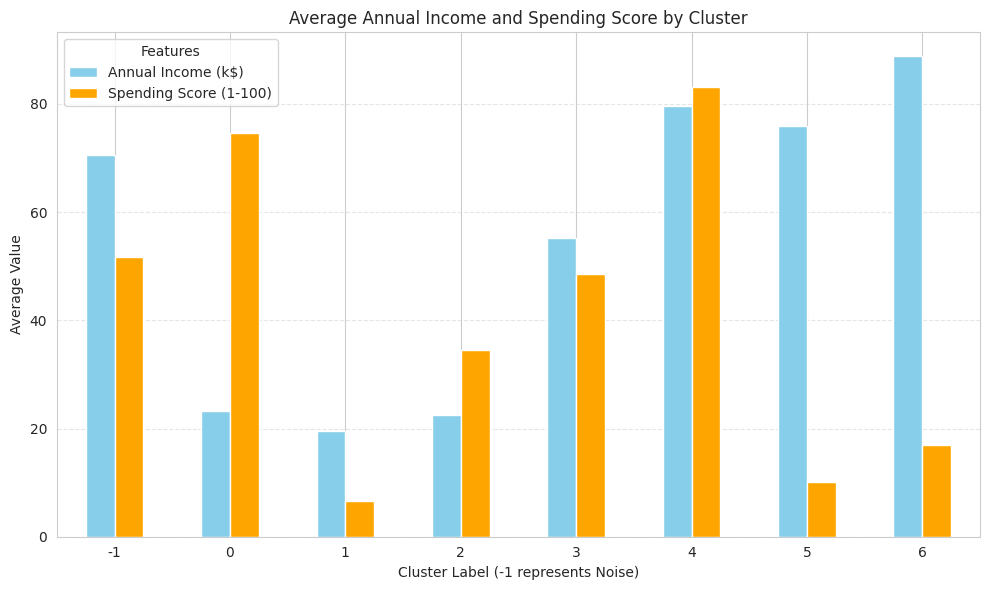

In [5]:

# Task 6: Analyze Results and Cluster Statistics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Append cluster labels to the original dataset
df['Cluster'] = labels

# Display dataset with cluster labels
print("Dataset with Cluster Labels:")
display(df.head())

# Calculate mean statistics for each cluster
print("\nCluster Statistics (Mean Values):")

cluster_stats = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

display(cluster_stats)

# Count customers in each cluster
print("\nNumber of Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# Analyze noise points (label -1)
noise_points = df[df['Cluster'] == -1]

print("\nNumber of Noise Points:", len(noise_points))

print("\nNoise Point Details:")
display(noise_points[
    ['CustomerID', 'Gender', 'Age',
     'Annual Income (k$)', 'Spending Score (1-100)']
])

# Visualize cluster statistics
cluster_stats.plot(
    kind='bar',
    figsize=(10, 6),
    color=['skyblue', 'orange']
)

plt.title('Average Annual Income and Spending Score by Cluster')
plt.xlabel('Cluster Label (-1 represents Noise)')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(title='Features')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.